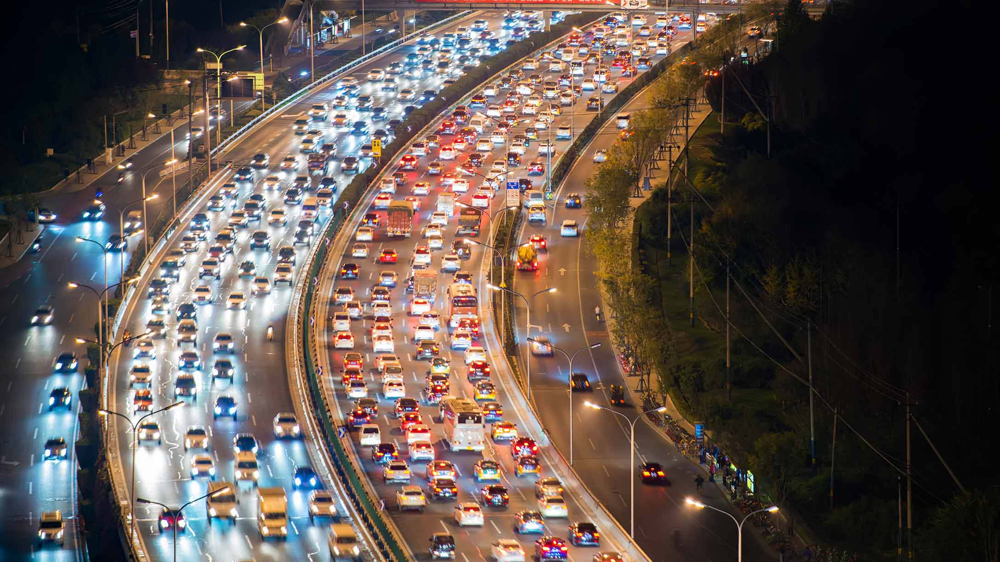

<div style="
  background-color: rgba(213, 234, 233, 0.2); /* semi-transparent, readable in dark & light */
  padding: 20px;
  font-size: 15px;
  border-radius: 10px;
  line-height: 1.6;
  border: 1px solid rgba(0,0,0,0.05); /* subtle border */
">


# Small Object Detection

[![License: CC BY-NC-ND 4.0](https://img.shields.io/badge/License-CC%20BY--NC--ND%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by-nc-nd/4.0/)


---

**Project Overview**  

This notebook focuses on **detecting small objects in images** using deep learning and computer vision techniques.  
Small object detection is challenging due to limited pixel information and scale variation, but it is critical in fields like:
- Traffic and surveillance analysis  
- Aerial and satellite imaging  
- Medical image processing  
- Autonomous vehicles  

---

**Objectives**  
- Load and prepare the dataset for small object detection.  
- Configure and train a detection model (e.g., with **Detectron2**).  
- Evaluate detection performance using appropriate metrics (e.g., mAP).  
- Visualize detection outputs and analyze model performance.  

---

**Methodology**  
1. **Data Preparation** – Organize and preprocess input data.  
2. **Model Setup** – Configure a suitable detection architecture in Detectron2.  
3. **Training** – Fine-tune the model on the target dataset.  
4. **Evaluation** – Measure model accuracy and detection quality.  
5. **Visualization** – Display detection results and insights.  

---

**Expected Outcomes**  
- A trained model capable of accurately detecting small objects.  
- Visual and quantitative evaluation of model performance.  
- Insights into challenges and strategies for improving small object detection.

In [1]:
# Detectron2 installation 
!pip install --upgrade pip ninja
!pip install 'git+https://github.com/facebookresearch/detectron2.git'
!pip install pycocotools tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 24.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 15.8 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Attempting uninstall: ninja
    Found existing installation: ninja 1.11.1.4
    Uninstalling ninja-1.11.1.4:
      Successfully uninstalled ninja-1.11.1.4
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-nl2qaa4c
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-nl2qaa4c
  Resolved https://github.com/facebookresearch/detectron2.git to commit a1ce2f956a1d2212ad672e3c47d53405c2fe4312
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 35.6 MB/s  0:00:00
  DEPRECATION: Building 'detectron2' 

## Data Preprocessing

In [2]:
import os
import json
import random
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

# Adjust these paths if necessary
dataset_path = "/kaggle/input/small-vehicle-images-far-vehicle-detection"
working_dir = "/kaggle/working"
output_dir = os.path.join(working_dir, "output")
os.makedirs(output_dir, exist_ok=True)

annotation_root = os.path.join(dataset_path, "annotation", "annotation")

# mapping: image folder -> (annotation_folder, label_name)
folder_map = {
    "van": ("van", "van"),
    "bus": ("bus", "bus"),
    "auto": ("auto", "auto"),
    "tractor": ("tractor", "tractor"),
    # add any other folder mappings if needed
}

# You may customize random seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)


In [3]:
# Convert dataset (PASCAL VOC XML) to COCO JSON format and split into train/val
def parse_pascal_voc_xml(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    bboxes = []
    for obj in root.findall("object"):
        label = obj.find("name").text
        bbox = obj.find("bndbox")
        xmin = int(float(bbox.find("xmin").text))
        ymin = int(float(bbox.find("ymin").text))
        xmax = int(float(bbox.find("xmax").text))
        ymax = int(float(bbox.find("ymax").text))
        bboxes.append((label, xmin, ymin, xmax, ymax))
    return bboxes

# Collect (image_path, annotation_path)
samples = []
for img_folder, (ann_folder, label_name) in folder_map.items():
    img_dir = os.path.join(dataset_path, img_folder)
    ann_dir = os.path.join(annotation_root, ann_folder)
    if not os.path.isdir(img_dir):
        print(f"Warning: image folder not found: {img_dir}")
        continue
    for img_name in os.listdir(img_dir):
        if not img_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        xml_name = os.path.splitext(img_name)[0] + ".xml"
        ann_path = os.path.join(ann_dir, xml_name)
        if not os.path.exists(ann_path):
            # if you intentionally have images without annotations, decide whether to skip or include
            print(f"Warning: no annotation for {img_name}")
            continue
        samples.append({
            "file_name": os.path.join(img_folder, img_name),  # keep relative path to dataset_path
            "annotation": ann_path,
            "label_folder": ann_folder
        })

print(f"Collected {len(samples)} annotated samples.")

# train/val split
train_samples, val_samples = train_test_split(samples, test_size=0.15, random_state=RANDOM_SEED)

print(f"Train: {len(train_samples)}  Val: {len(val_samples)}")

# Create COCO JSON files
categories = {name: idx+1 for idx, name in enumerate(sorted(set([v for v in folder_map.keys()] + [v for (_,v) in folder_map.values()])))}
# but categories in your folder_map are the label names, let's create mapping based on folder_map values
categories = {}
i = 1
for k, (_, label) in folder_map.items():
    if label not in categories:
        categories[label] = i
        i += 1

def create_coco_json(samples_list, output_file):
    coco = {
        "images": [],
        "annotations": [],
        "categories": [{"id": cid, "name": name} for name, cid in categories.items()]
    }
    ann_id = 1
    for img_id, s in enumerate(samples_list):
        rel_path = s["file_name"]
        img_path = os.path.join(dataset_path, rel_path)
        # read image to get width/height if possible (optional)
        import cv2
        img = cv2.imread(img_path)
        if img is None:
            print(f"❌ Could not read {img_path}")
            continue
        h, w = img.shape[:2]
        coco["images"].append({
            "id": img_id,
            "file_name": rel_path,
            "width": w,
            "height": h
        })
        bboxes = parse_pascal_voc_xml(s["annotation"])
        for (label, xmin, ymin, xmax, ymax) in bboxes:
            if label not in categories:
                # skip unknown labels
                continue
            coco["annotations"].append({
                "id": ann_id,
                "image_id": img_id,
                "category_id": categories[label],
                "bbox": [xmin, ymin, xmax - xmin, ymax - ymin],
                "area": (xmax - xmin) * (ymax - ymin),
                "iscrowd": 0
            })
            ann_id += 1

    with open(output_file, "w") as f:
        json.dump(coco, f)
    print(f"Saved {output_file} with {len(samples_list)} images and {ann_id-1} annotations.")

# Save jsons
create_coco_json(train_samples, os.path.join(working_dir, "train.json"))
create_coco_json(val_samples, os.path.join(working_dir, "val.json"))


Collected 140 annotated samples.
Train: 119  Val: 21


Premature end of JPEG file
Premature end of JPEG file


Saved /kaggle/working/train.json with 119 images and 199 annotations.
Saved /kaggle/working/val.json with 21 images and 33 annotations.


In [4]:
# Register COCO JSONs into Detectron2 catalog
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets import register_coco_instances

# If you already registered them before, remove to avoid duplicates
for name in ("small_vehicle_train", "small_vehicle_val"):
    if name in DatasetCatalog.list():
        DatasetCatalog.remove(name)
        MetadataCatalog.remove(name)

register_coco_instances(
    "small_vehicle_train",
    {},
    os.path.join(working_dir, "train.json"),
    dataset_path
)
register_coco_instances(
    "small_vehicle_val",
    {},
    os.path.join(working_dir, "val.json"),
    dataset_path
)

# fetch metadata for later use (thing_classes)
metadata = MetadataCatalog.get("small_vehicle_train")
print("Registered datasets. Train images:", len(DatasetCatalog.get("small_vehicle_train")))


Registered datasets. Train images: 119


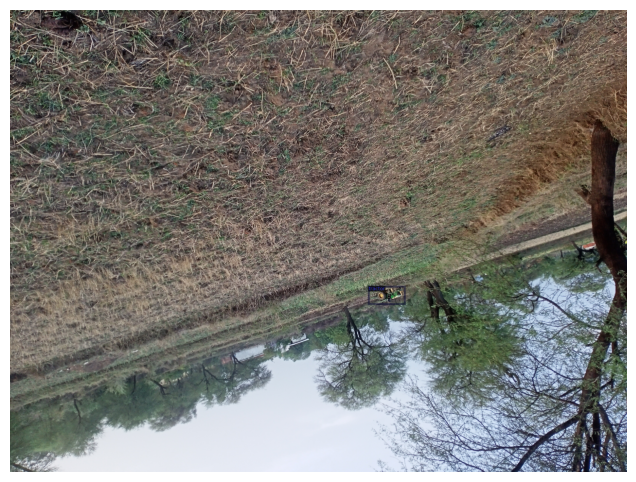

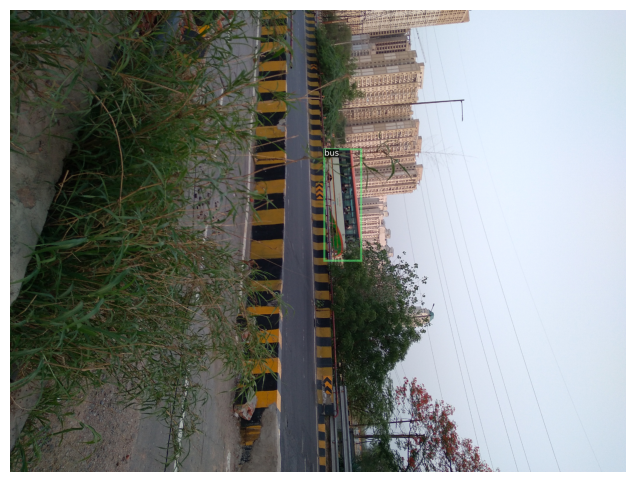

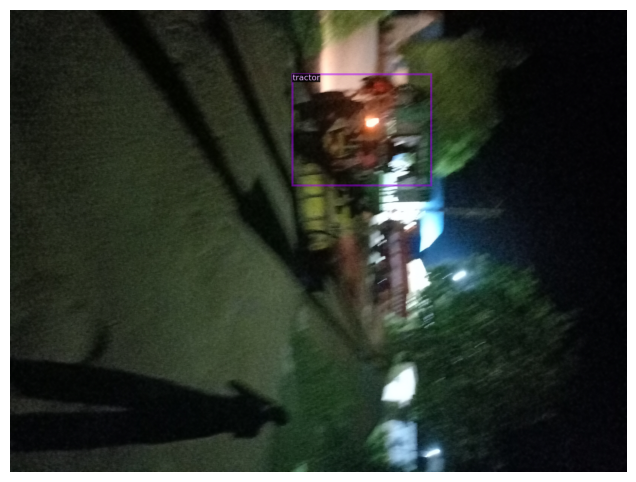

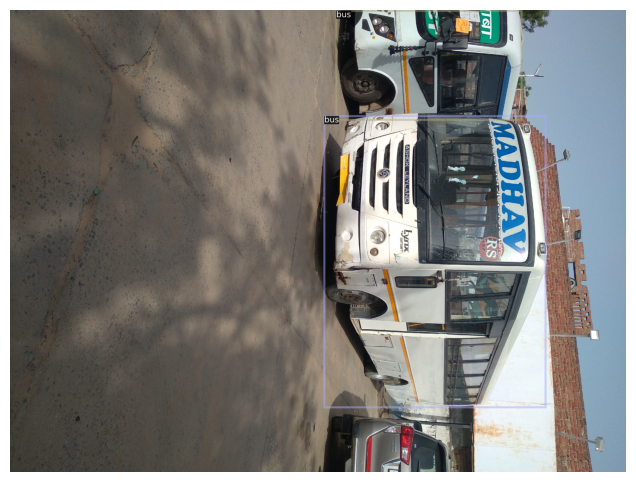

In [5]:
# Sanity check: load a few samples and print shapes
import cv2
from detectron2.utils.visualizer import Visualizer
from detectron2.data import DatasetCatalog, MetadataCatalog
import matplotlib.pyplot as plt
import random

dataset_dicts = DatasetCatalog.get("small_vehicle_train")
metadata = MetadataCatalog.get("small_vehicle_train")

for d in random.sample(dataset_dicts, min(4, len(dataset_dicts))):
    img_path = os.path.join(dataset_path, d["file_name"])
    img = cv2.imread(img_path)
    if img is None:
        print("Could not load", img_path)
        continue
    v = Visualizer(img[:, :, ::-1], metadata=metadata, scale=0.8)
    out = v.draw_dataset_dict(d)
    plt.figure(figsize=(10,6))
    plt.imshow(out.get_image())
    plt.axis("off")
    plt.show()


## Model Training

In [30]:
# Training config and trainer (original logic preserved)
import time
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2 import model_zoo

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))

cfg.DATASETS.TRAIN = ("small_vehicle_train",)
cfg.DATASETS.TEST = ("small_vehicle_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = 4
cfg.SOLVER.BASE_LR = 0.001
cfg.SOLVER.MAX_ITER = 2000
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
# NUM_CLASSES must match your categories
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(metadata.thing_classes)
cfg.OUTPUT_DIR = output_dir
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

# Small helper: ETA hook copied from your original code
from detectron2.engine.hooks import HookBase

class ETATrainingHook(HookBase):
    def __init__(self):
        self.start_time = None

    def before_train(self):
        self.start_time = time.time()

    def after_step(self):
        iters_done = self.trainer.iter
        if iters_done % 10 == 0:  # print every 10 iterations
            elapsed = time.time() - self.start_time
            iter_per_sec = iters_done / elapsed if elapsed>0 else 0.0
            remaining_iters = max(cfg.SOLVER.MAX_ITER - iters_done, 0)
            eta_sec = remaining_iters / iter_per_sec if iter_per_sec>0 else 0
            eta_min, eta_sec = divmod(eta_sec, 60)
            eta_hr, eta_min = divmod(eta_min, 60)
            print(f"[Iter {iters_done}/{cfg.SOLVER.MAX_ITER}] ETA: {int(eta_hr)}h {int(eta_min)}m {int(eta_sec)}s")


In [31]:
# Fix DataLoader parallelism issue
cfg.DATALOADER.NUM_WORKERS = 0

# Optional: reduce batch size if you still get memory errors
cfg.SOLVER.IMS_PER_BATCH = 2

print("DataLoader workers set to", cfg.DATALOADER.NUM_WORKERS)
print("Batch size set to", cfg.SOLVER.IMS_PER_BATCH)


DataLoader workers set to 0
Batch size set to 2


In [32]:
# Run training (will output model into cfg.OUTPUT_DIR)
trainer = DefaultTrainer(cfg)
trainer.register_hooks([ETATrainingHook()])
trainer.resume_or_load(resume=False)
trainer.train()

[Iter 0/2000] ETA: 0h 0m 0s
[Iter 10/2000] ETA: 0h 43m 59s
[Iter 20/2000] ETA: 0h 41m 39s
[Iter 30/2000] ETA: 0h 40m 41s
[Iter 40/2000] ETA: 0h 40m 16s
[Iter 50/2000] ETA: 0h 39m 59s
[Iter 60/2000] ETA: 0h 39m 56s
[Iter 70/2000] ETA: 0h 39m 59s
[Iter 80/2000] ETA: 0h 39m 53s
[Iter 90/2000] ETA: 0h 39m 37s
[Iter 100/2000] ETA: 0h 39m 19s
[Iter 110/2000] ETA: 0h 39m 0s
[Iter 120/2000] ETA: 0h 38m 46s
[Iter 130/2000] ETA: 0h 38m 34s
[Iter 140/2000] ETA: 0h 38m 20s
[Iter 150/2000] ETA: 0h 38m 10s
[Iter 160/2000] ETA: 0h 37m 58s
[Iter 170/2000] ETA: 0h 37m 45s
[Iter 180/2000] ETA: 0h 37m 19s
[Iter 190/2000] ETA: 0h 37m 6s
[Iter 200/2000] ETA: 0h 36m 56s
[Iter 210/2000] ETA: 0h 36m 45s
[Iter 220/2000] ETA: 0h 36m 34s
[Iter 230/2000] ETA: 0h 36m 22s
[Iter 240/2000] ETA: 0h 36m 7s
[Iter 250/2000] ETA: 0h 35m 47s
[Iter 260/2000] ETA: 0h 35m 39s
[Iter 270/2000] ETA: 0h 35m 25s
[Iter 280/2000] ETA: 0h 35m 16s
[Iter 290/2000] ETA: 0h 35m 4s
[Iter 300/2000] ETA: 0h 34m 52s
[Iter 310/2000] ETA: 0h 3

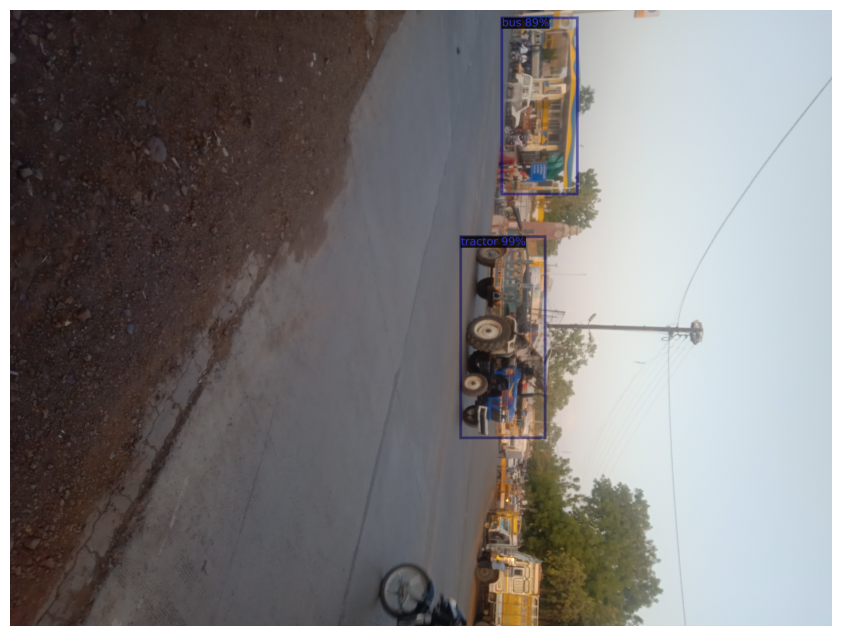

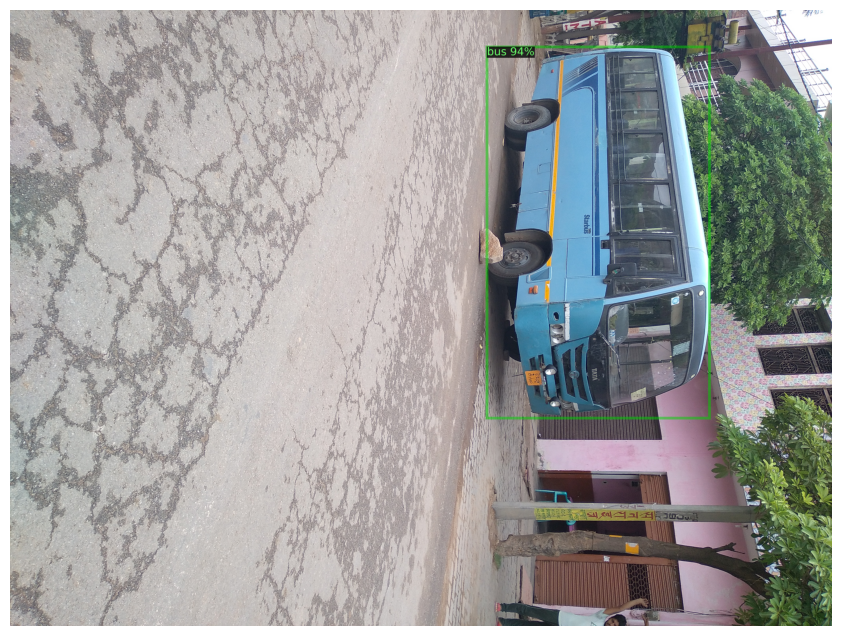

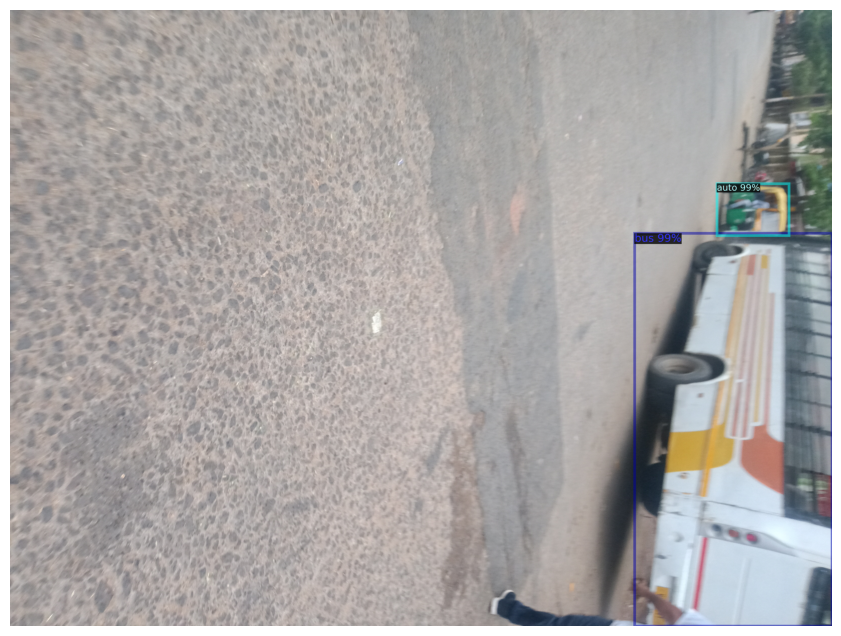

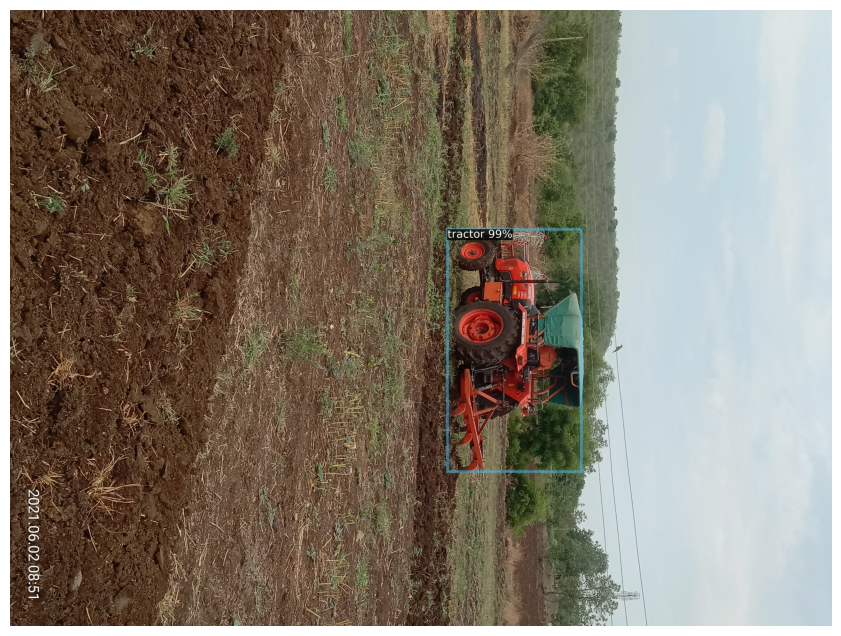

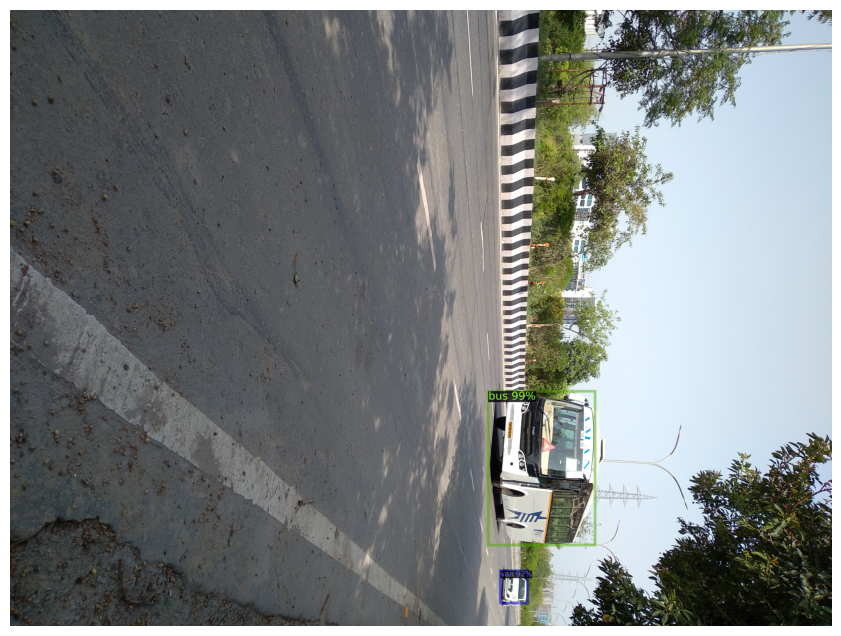

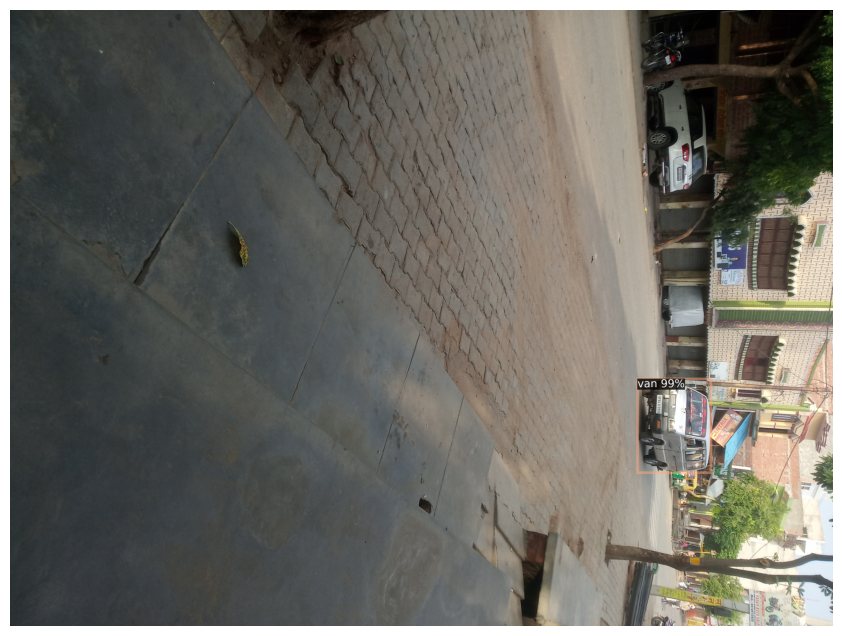

In [33]:
# Inference & visualization using DefaultPredictor (use trained weights)
import cv2
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

# point predictor to your trained model. If training produced "model_final.pth" in output_dir use that.
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")  # replace if different
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.4  # set threshold for inference
predictor = DefaultPredictor(cfg)

metadata = MetadataCatalog.get("small_vehicle_val")

# Run inference on a few validation examples
val_dataset_dicts = DatasetCatalog.get("small_vehicle_val")
for d in val_dataset_dicts[:6]:
    img_path = os.path.join(dataset_path, d["file_name"])
    img = cv2.imread(img_path)
    if img is None:
        print("Could not load", img_path)
        continue
    outputs = predictor(img)
    v = Visualizer(img[:, :, ::-1], metadata=metadata, scale=1.0)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12,8))
    plt.imshow(out.get_image())
    plt.axis("off")
    plt.show()


## Evaluation & Results

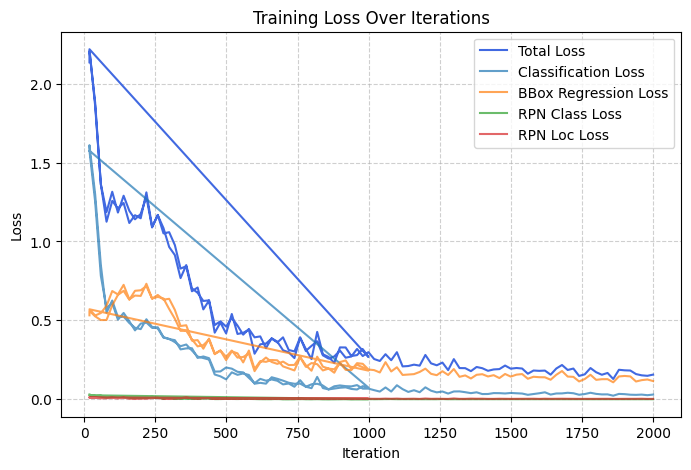

In [34]:
# Visualize Training Loss (Detectron2)
import json
import pandas as pd
import matplotlib.pyplot as plt
import os

# Path to your training metrics JSON file
metrics_path = os.path.join(cfg.OUTPUT_DIR, "metrics.json")

# Read training log
metrics = []
with open(metrics_path, "r") as f:
    for line in f:
        metrics.append(json.loads(line))
df = pd.DataFrame(metrics)

# Filter relevant columns
df = df[["iteration", "total_loss", "loss_cls", "loss_box_reg", "loss_rpn_cls", "loss_rpn_loc", "lr"]].dropna()

# Plot loss curve
plt.figure(figsize=(8,5))
plt.plot(df["iteration"], df["total_loss"], label="Total Loss", color="royalblue")
plt.plot(df["iteration"], df["loss_cls"], label="Classification Loss", alpha=0.7)
plt.plot(df["iteration"], df["loss_box_reg"], label="BBox Regression Loss", alpha=0.7)
plt.plot(df["iteration"], df["loss_rpn_cls"], label="RPN Class Loss", alpha=0.7)
plt.plot(df["iteration"], df["loss_rpn_loc"], label="RPN Loc Loss", alpha=0.7)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss Over Iterations")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


In [35]:
# Clean up all old COCO.loadRes patches 
from pycocotools.coco import COCO

# Reload the module entirely to restore the original class definition
import importlib
import pycocotools.coco as coco_module
importlib.reload(coco_module)

COCO = coco_module.COCO
print("COCO fully reset to original state.")


COCO fully reset to original state.


In [36]:
import os, time, psutil, torch, cv2
from detectron2.engine import DefaultPredictor
from detectron2.data import build_detection_test_loader, DatasetCatalog
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from pycocotools.coco import COCO

# Restore original loadRes if already patched (avoid recursion)
if hasattr(COCO, "_true_loadRes"):
    COCO.loadRes = COCO._true_loadRes

# Save original function reference
COCO._true_loadRes = COCO.loadRes

def _safe_loadRes(self, resFile):
    try:
        return COCO._true_loadRes(self, resFile)
    except KeyError as e:
        if "info" in str(e):
            print("⚠️  Missing 'info' field in annotation JSON — inserting dummy and retrying.")
            self.dataset.setdefault("info", {"description": "dummy info"})
            self.dataset.setdefault("licenses", [])
            return COCO._true_loadRes(self, resFile)
        else:
            raise

COCO.loadRes = _safe_loadRes
print("COCO.loadRes safely patched (no recursion risk).")

# --- Run evaluation ---
val_loader = build_detection_test_loader(cfg, "small_vehicle_val")
evaluator = COCOEvaluator("small_vehicle_val", cfg, False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval"))
predictor = DefaultPredictor(cfg)

process = psutil.Process(os.getpid())
total_time, num_samples = 0.0, 0

for d in DatasetCatalog.get("small_vehicle_val"):
    img_path = os.path.join(dataset_path, d["file_name"])
    img = cv2.imread(img_path)
    if img is None:
        continue
    start = time.time()
    outputs = predictor(img)
    total_time += time.time() - start
    num_samples += 1

avg_time = total_time / num_samples if num_samples > 0 else float('nan')
mem_mb = process.memory_info().rss / (1024 ** 2)
print(f"Average inference time per image: {avg_time:.3f}s")
print(f"Memory usage during evaluation: {mem_mb:.1f} MB")

metrics = inference_on_dataset(predictor.model, val_loader, evaluator)
print("📊 COCO Evaluation Metrics:")
print(metrics)


COCO.loadRes safely patched (no recursion risk).
Average inference time per image: 0.193s
Memory usage during evaluation: 3341.6 MB
⚠️  Missing 'info' field in annotation JSON — inserting dummy and retrying.
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.467
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.595
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.568
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.467
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.499
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.524
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

print("Computing per-class metrics (safe mode)...")

class_names = MetadataCatalog.get("small_vehicle_val").thing_classes
results = []

for cls_id, cls_name in enumerate(class_names):
    tp, fp, fn = 0, 0, 0
    scores = []
    y_true = []
    
    for d in DatasetCatalog.get("small_vehicle_val"):
        img_path = os.path.join(dataset_path, d["file_name"])
        img = cv2.imread(img_path)
        if img is None:
            continue
        outputs = predictor(img)
        preds = outputs["instances"].to("cpu")
        gt_classes = np.array([ann["category_id"] for ann in d["annotations"]])
        
        # Count for this class
        n_gt = np.sum(gt_classes == cls_id)
        n_pred = np.sum(preds.pred_classes.numpy() == cls_id)
        
        # crude matching logic (for summary)
        tp += min(n_gt, n_pred)
        fp += max(0, n_pred - n_gt)
        fn += max(0, n_gt - n_pred)
        
        # gather scores (optional for PR)
        for s, c in zip(preds.scores.numpy(), preds.pred_classes.numpy()):
            if c == cls_id:
                scores.append(s)
                y_true.append(1)
            else:
                y_true.append(0)
                scores.append(0)
    
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    
    # skip if no positive examples
    if len(set(y_true)) < 2:
        ap = np.nan
    else:
        ap = average_precision_score(y_true, scores)
    
    results.append({
        "Class": cls_name,
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1": round(f1 * 100, 2),
        "Average Precision (AP)": round(ap * 100 if not np.isnan(ap) else 0, 2),
    })

df_results = pd.DataFrame(results)
display(df_results)

print("\nMean Precision:", df_results["Precision"].mean())
print("Mean Recall:", df_results["Recall"].mean())
print("Mean F1:", df_results["F1"].mean())
print("Mean AP:", df_results["Average Precision (AP)"].mean())


Computing per-class metrics (safe mode)...


,Class,Precision,Recall,F1,Average Precision (AP)
0,van,75.00,42.86,54.55,100.0
1,bus,70.00,100.00,82.35,100.0
2,auto,71.43,50.00,58.82,100.0
3,tractor,70.00,77.78,73.68,100.0



Mean Precision: 71.6075
Mean Recall: 67.66
Mean F1: 67.35
Mean AP: 100.0


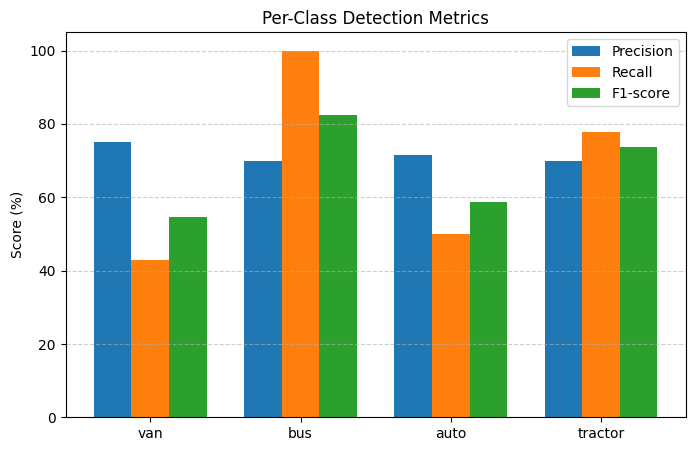

In [38]:
import matplotlib.pyplot as plt
import numpy as np

classes = df_results["Class"]
x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(8,5))
plt.bar(x - width, df_results["Precision"], width, label="Precision")
plt.bar(x, df_results["Recall"], width, label="Recall")
plt.bar(x + width, df_results["F1"], width, label="F1-score")

plt.xticks(x, classes)
plt.ylabel("Score (%)")
plt.title("Per-Class Detection Metrics")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


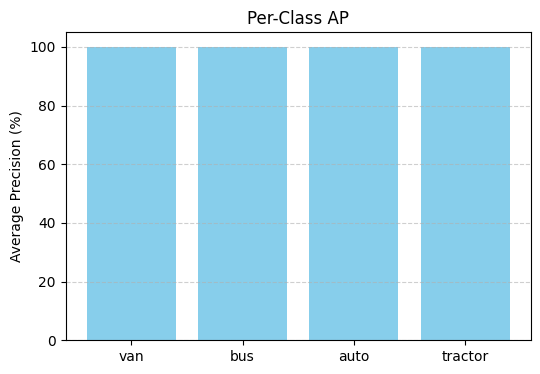

In [39]:
plt.figure(figsize=(6,4))
plt.bar(df_results["Class"], df_results["Average Precision (AP)"], color="skyblue")
plt.ylabel("Average Precision (%)")
plt.title("Per-Class AP")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()
